# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / 1_000_000

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (1920 * 1080 * 3 * frames_per_day * 400) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3 * 10 * 60 * 60 * 24 * 400) / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

The smaller frame loses fine details like a face or a hand-held object. At 10 fps, a quick movement between frames can disappear too, so we could miss exactly what the person did.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

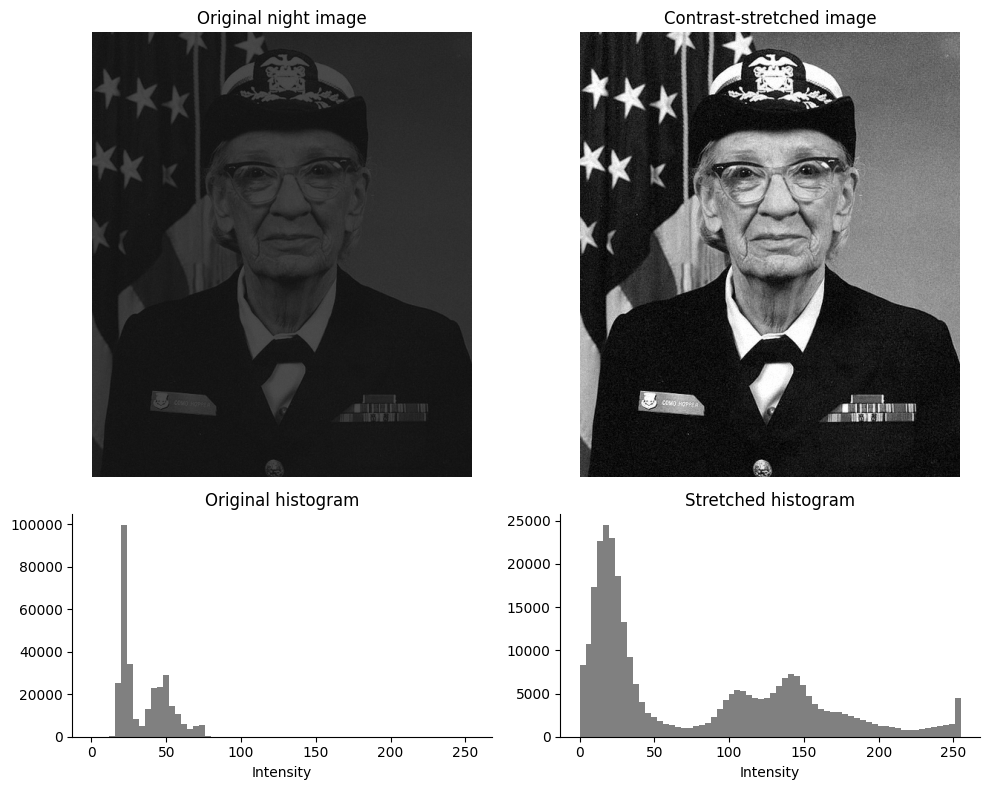

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) * 255 / (p99 - p1), 0, 255)

c_after = michelson(*np.percentile(stretched, [99, 1]))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# Original image and its histogram
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original night image")
axes[0, 0].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 0].set_title("Original histogram")
axes[1, 0].set_xlabel("Intensity")

# Contrast-stretched image and its histogram
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-stretched image")
axes[0, 1].axis("off")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 1].set_title("Stretched histogram")
axes[1, 1].set_xlabel("Intensity")


plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

The histogram is bunched up on the dark, low-contrast end. Stretching spreads those values out, so the image is easier to read, but it does not add any detail that was not recorded. A histogram also ignores where the pixels are, so it cannot tell us what the picture actually shows.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (speed < 3 px/s): 68.7 to 78.1 s
Running (speed > 25 px/s): 78.6 to 86.0 s


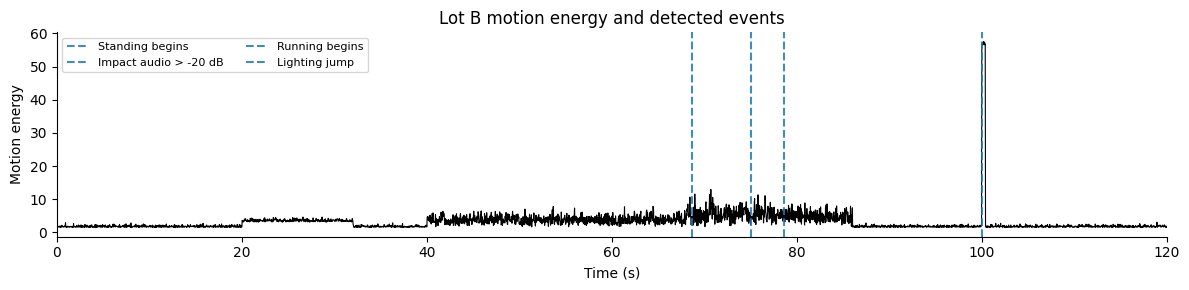

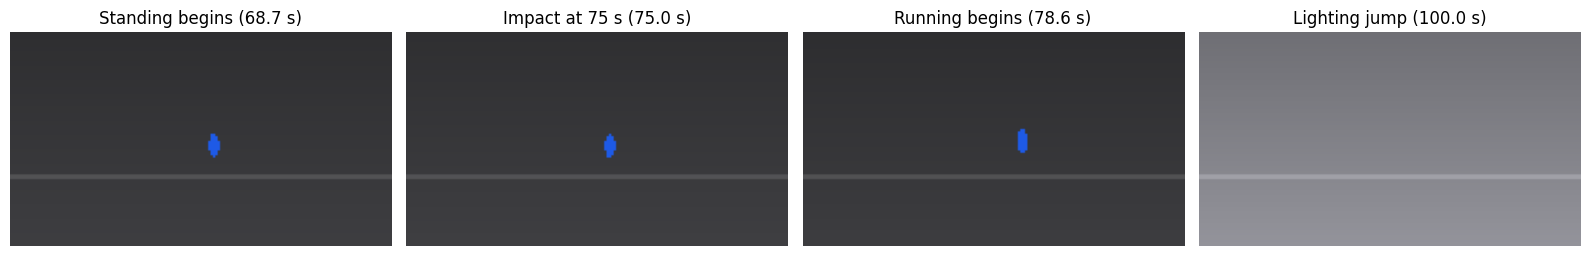

In [4]:
# TODO 1: person speed (px/s)
dx = cctv["person_x"] - cctv["person_x"].shift(FPS)
dy = cctv["person_y"] - cctv["person_y"].shift(FPS)
speed = np.sqrt(dx**2 + dy**2)
speed[cctv["person_x"].isna() | cctv["person_y"].isna() |
      cctv["person_x"].shift(FPS).isna() | cctv["person_y"].shift(FPS).isna()] = np.nan

# Report the first and last timestamps that meet each speed threshold.
standing_mask = speed.notna() & (speed < 3)
running_mask = speed.notna() & (speed > 25)
standing_times = cctv.loc[standing_mask, "time_s"]
running_times = cctv.loc[running_mask, "time_s"]
if not standing_times.empty:
    print(f"Standing (speed < 3 px/s): {standing_times.iloc[0]:.1f} to {standing_times.iloc[-1]:.1f} s")
else:
    print("No standing interval detected.")
if not running_times.empty:
    print(f"Running (speed > 25 px/s): {running_times.iloc[0]:.1f} to {running_times.iloc[-1]:.1f} s")
else:
    print("No running interval detected.")

standing_event_idx = int(standing_times.index[0]) if not standing_times.empty else None
running_event_idx = int(running_times.index[0]) if not running_times.empty else None


# TODO 3: event frame indices
audio_event_idx = int(cctv.index[cctv["audio_level_db"] > -20][0])
lighting_event_idx = int(cctv.index[cctv["mean_brightness"].diff() > 40][0])

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv["time_s"], cctv["motion_energy"], linewidth=0.8, color="black")
ax.set_title("Lot B motion energy and detected events")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion energy")
ax.set_xlim(0, 120)

events = []
if standing_event_idx is not None:
    events.append((standing_event_idx, "Standing begins"))
if audio_event_idx is not None:
    events.append((audio_event_idx, "Impact audio > -20 dB"))
if running_event_idx is not None:
    events.append((running_event_idx, "Running begins"))
if lighting_event_idx is not None:
    events.append((lighting_event_idx, "Lighting jump"))
for idx, label in events:
    ax.axvline(cctv.loc[idx, "time_s"], linestyle="--", alpha=0.85, label=label)
ax.legend(loc="upper left", ncol=2, fontsize=8)

plt.tight_layout(); plt.show()

# One representative frame at the start of each detected event
keyframes = [("Standing begins", standing_event_idx),
             ("Impact at 75 s", audio_event_idx),
             ("Running begins", running_event_idx),
             ("Lighting jump", lighting_event_idx)]
keyframes = [(label, idx) for label, idx in keyframes if idx is not None]
fig, axes = plt.subplots(1, len(keyframes), figsize=(4 * len(keyframes), 3))
if len(keyframes) == 1:
    axes = [axes]
for ax, (label, idx) in zip(axes, keyframes):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{label} ({cctv.loc[idx, 'time_s']:.1f} s)")
    ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

Uniform frames every 20 seconds would likely miss the bang at 75 s and the run starting at 78.6 s. The approach here is content-based keyframing, so frames are picked around actual changes instead of fixed intervals.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

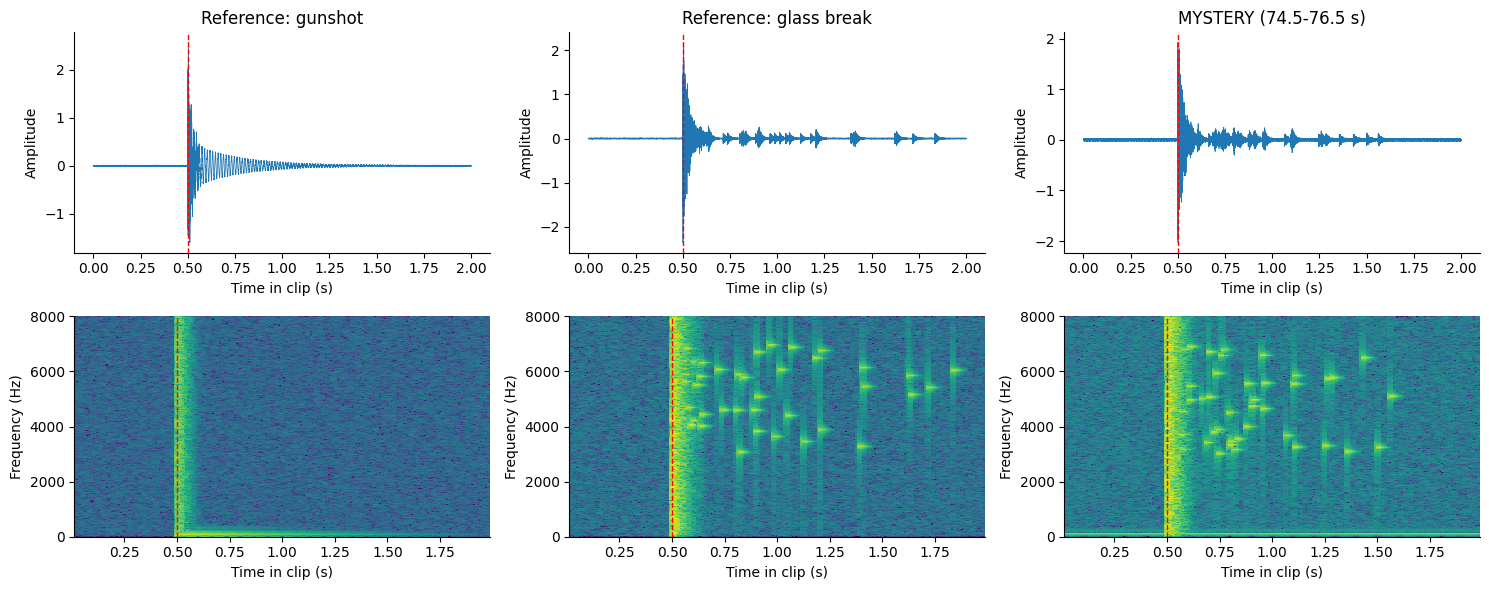

{'Reference: gunshot': np.float64(0.0030555631226980044), 'Reference: glass break': np.float64(0.9903944120505495), 'MYSTERY (74.5-76.5 s)': np.float64(0.8792270448446914)}
Verdict: the mystery sound is more consistent with a glass break reference based on high-frequency energy.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col, (name, clip_x) in enumerate(clips.items()):
    clip_t = np.arange(clip_x.size) / FS
    axes[0, col].plot(clip_t, clip_x, linewidth=0.55)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time in clip (s)")
    axes[0, col].set_ylabel("Amplitude")
    axes[0, col].axvline(0.5, color="red", linestyle="--", linewidth=1)

    freqs, spec_t, power = signal.spectrogram(clip_x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(spec_t, freqs, 10 * np.log10(power + 1e-12), shading="auto")
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time in clip (s)")
    axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].axvline(0.5, color="red", linestyle="--", linewidth=1)


plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, clip_x in clips.items():
    freqs, spec_t, power = signal.spectrogram(clip_x, fs=FS, nperseg=512, noverlap=384)
    after_impact = (spec_t >= 0.7) & (spec_t <= 1.7)
    total_energy = power[:, after_impact].sum()
    high_energy = power[freqs >= 3000, :][:, after_impact].sum()
    hf_fraction[name] = high_energy / total_energy if total_energy else 0.0

print(hf_fraction)
gunshot_score = abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: gunshot"])
glass_score = abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: glass break"])
verdict = "glass break" if glass_score < gunshot_score else "gunshot"
print(f"Verdict: the mystery sound is more consistent with a {verdict} reference based on high-frequency energy.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

No, the waveforms mainly show that all three clips have a loud impact. The spectrogram adds time, frequency and magnitude, and the scattered high-frequency specks after the impact point to glass breaking.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

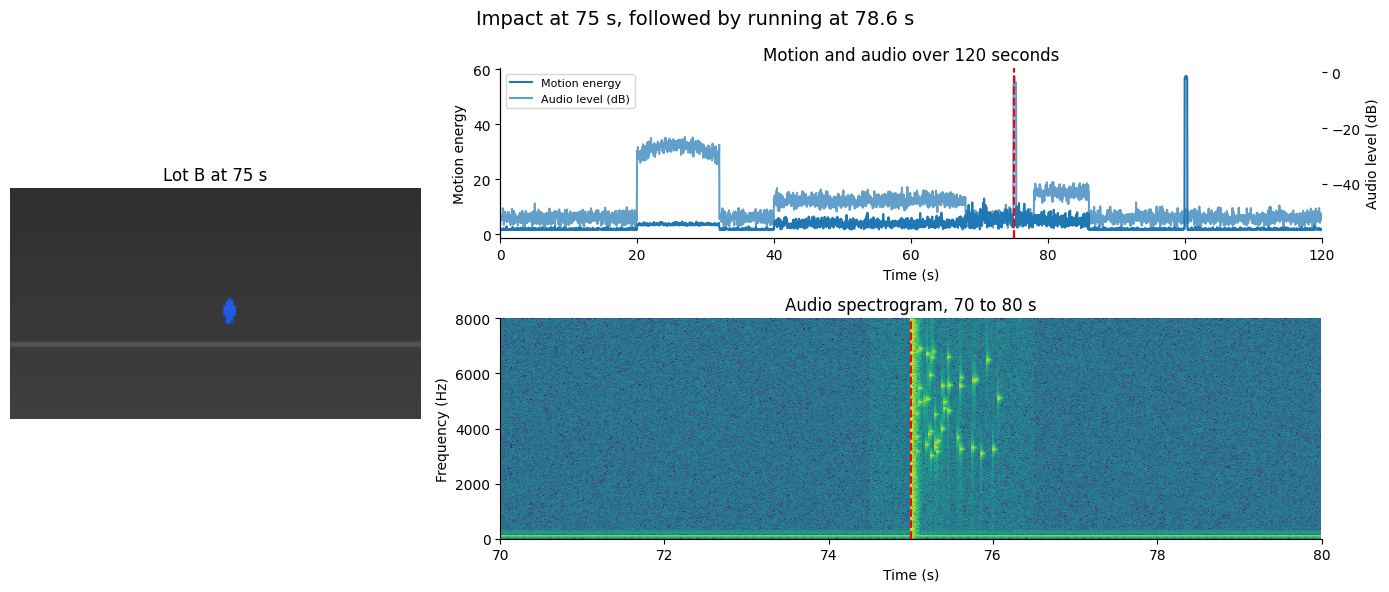

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
idx_sel = int((cctv["time_s"] - t_sel).abs().idxmin())

# Left: frame at the impact time
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[idx_sel]))
ax_frame.set_title("Lot B at 75 s")
ax_frame.axis("off")

# Top right: full camera timeline with motion and audio levels
ax_timeline = fig.add_subplot(gs[0, 1])
line_motion, = ax_timeline.plot(cctv["time_s"], cctv["motion_energy"], label="Motion energy")
ax_timeline.set_xlim(0, 120)
ax_timeline.set_xlabel("Time (s)")
ax_timeline.set_ylabel("Motion energy")
ax_audio = ax_timeline.twinx()
line_audio, = ax_audio.plot(cctv["time_s"], cctv["audio_level_db"], alpha=0.7, label="Audio level (dB)")
ax_audio.set_ylabel("Audio level (dB)")
for axis in (ax_timeline, ax_audio):
    axis.axvline(t_sel, color="red", linestyle="--", linewidth=1.5)
ax_timeline.legend([line_motion, line_audio], [line_motion.get_label(), line_audio.get_label()], loc="upper left", fontsize=8)
ax_timeline.set_title("Motion and audio over 120 seconds")

# Bottom right: spectrogram aligned to the same absolute timeline
ax_spec = fig.add_subplot(gs[1, 1])
freqs, spec_t, power = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
abs_spec_t = t_audio[0] + spec_t
ax_spec.pcolormesh(abs_spec_t, freqs, 10 * np.log10(power + 1e-12), shading="auto")
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlim(70, 80)
ax_spec.axvline(t_sel, color="red", linestyle="--", linewidth=1.5)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio spectrogram, 70 to 80 s")
fig.suptitle("Impact at 75 s, followed by running at 78.6 s", fontsize=14)


plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

The bang would appear two seconds away from the video moment, which could make us wrongly link it to what the person does next. The spectrogram panel would show the mismatch because the loud sound would not line up with the 75 s marker.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

Someone appears in Lot B around 40 s, the bang hits at 75.0 s, they run from 78.6 to 86.0 s, and the lights jump at 100.0 s. I'd put the timeline first because it shows the pattern, then the change and event, without making Security dig through the clip. The spectrogram looks more like the glass reference, with scattered high-frequency energy after the impact. For storage, I would use 640×360 at 10 fps instead of keeping all 400 cameras at 1080p/30. Keep the original audio around 75 s, because losing that would make the bang much harder to identify.